# CS781 Phase 3 — IA3 on the decoder + BiLSTM-CRF

**IA3** (Liu et al. 2022) learns three element-wise rescaling vectors per block —
`l_k ⊙ (W_k x)`, `l_v ⊙ (W_v x)`, and `W_down(l_ff ⊙ h)` on the FFN intermediate.
All initialised to **1**, so the model starts exactly at the pretrained function and learns
to *inhibit* (l<1) or *amplify* (l>1) individual channels.

Parameter count: (256 + 256 + 2048) x 19 = **48,640** — 8x fewer than the DoRA run's 408K.

**Written by hand, not via PEFT.** IA3 is three vectors and three multiplications; after the
torchao fight it is not worth the dependency, and a plain `nn.Parameter` makes the
interpretation in CELL 11 trivial instead of guessing at PEFT container types.

## This notebook runs a controlled comparison

The DoRA run couldn't be compared to anything because the baseline lived in a different
session. Here both arms train in one run on identical data, splits, head and seeds:

| arm | backbone | cost |
|---|---|---|
| **A: frozen** | embeddings cached once | ~1 min for 3 seeds |
| **B: IA3 joint** | re-encoded every epoch | ~90 min |

CELL 12 reports A (mean ± std over 3 seeds) against B and says whether the gap clears the
measured ±0.026 dev noise floor.

## Fixing what starved the DoRA run

That run got ~740 optimiser steps (147 chunks / grad_accum 4 x 20 epochs) against the frozen
run's ~4,240, and its adapters moved 0.3-0.7%. Here: **`grad_accum=1`** (4x the steps at
identical wall clock), **`epochs=30`**, **`sent_sub_batch=32`** (peak memory was only 3.6 of
22 GiB, so this roughly halves epoch time), and **`ia3_lr=5e-3`** — IA3 vectors start at 1 and
move multiplicatively, so they need a far higher LR than LoRA-style additive adapters.

In [ ]:
# CELL 1 — ASSETS

from pathlib import Path
from google.colab import drive
from getpass import getpass
from huggingface_hub import HfApi, hf_hub_download
import os, re, sys, subprocess

subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"])

drive.mount("/content/drive")
DRIVE_ROOT = Path("/content/drive/MyDrive")

drive_files = []
for root, dirs, files in os.walk(DRIVE_ROOT):
    dirs[:] = [d for d in dirs if d not in {".Trash", ".ipynb_checkpoints", "node_modules"}]
    for fn in files: drive_files.append(Path(root) / fn)

def normalized_name(p): return re.sub(r" \(\d+\)(?=\.)", "", p.name).lower()

def locate_drive_file(filename, preferred_folder=None):
    tgt = filename.lower()
    m = [p for p in drive_files if p.name.lower() == tgt or normalized_name(p) == tgt]
    if preferred_folder:
        pref = [p for p in m if preferred_folder.lower() in str(p.parent).lower()]
        if pref: m = pref
    if not m: raise FileNotFoundError(f"Could not find {filename}")
    m.sort(key=lambda p: (p.name.lower() != tgt, len(p.parts), str(p).lower()))
    return m[0]

CKPT_PATH      = locate_drive_file("best.pt")
TOKENIZER_JSON = locate_drive_file("bpe_40k.json")
TOKENIZER_PY   = locate_drive_file("a1_tokenizer.py")

HF_REPO = "Exploration-Lab/CS-781-Capstone"
HF_TOKEN = getpass("HF read token: ")
api = HfApi()
phase3 = [f for f in api.list_repo_files(repo_id=HF_REPO, repo_type="dataset",
                                          token=HF_TOKEN) if "phase_3_rr/" in f.lower()]

def dl(filename):
    tgt = filename.lower()
    m = [f for f in phase3 if Path(f).name.lower() == tgt] or \
        [f for f in phase3 if normalized_name(Path(f)).lower() == tgt]
    if "test" in tgt:          pref = [f for f in m if "/test/" in f.lower()]
    elif "label_vocab" in tgt: pref = m
    else:                      pref = [f for f in m if "/train/" in f.lower()]
    return Path(hf_hub_download(repo_id=HF_REPO, filename=(pref or m)[0],
                                repo_type="dataset", token=HF_TOKEN))

CL_TRAIN, CL_DEV = dl("CL_train.json"), dl("CL_dev.json")
IT_TRAIN, IT_DEV = dl("IT_train.json"), dl("IT_dev.json")
CL_TEST, IT_TEST = dl("CL_test.json"), dl("IT_test.json")
LABEL_VOCAB = dl("label_vocab.json")
if str(TOKENIZER_PY.parent) not in sys.path: sys.path.insert(0, str(TOKENIZER_PY.parent))
print(f"Decoder: {CKPT_PATH}")

Mounted at /content/drive
HF read token: ··········


CL_train.json:   0%|          | 0.00/2.46M [00:00<?, ?B/s]

CL_dev.json:   0%|          | 0.00/336k [00:00<?, ?B/s]

IT_train.json:   0%|          | 0.00/1.51M [00:00<?, ?B/s]

IT_dev.json:   0%|          | 0.00/165k [00:00<?, ?B/s]

CL_test.json:   0%|          | 0.00/281k [00:00<?, ?B/s]

IT_test.json:   0%|          | 0.00/194k [00:00<?, ?B/s]

label_vocab.json:   0%|          | 0.00/340 [00:00<?, ?B/s]

Decoder: /content/drive/MyDrive/best.pt


In [ ]:
# CELL 2 — IMPORTS + CONFIG

import json, math, random, zipfile, time, html, unicodedata, copy
from dataclasses import dataclass
from collections import Counter, deque
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
from torch.amp import autocast, GradScaler
from torch.utils.checkpoint import checkpoint as grad_ckpt
from sklearn.metrics import f1_score, classification_report
from a1_tokenizer import BPETokenizer

OUTPUT_DIR = DRIVE_ROOT / "CS781_Phase3_IA3_outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print(f"GPU: {p.name} ({p.total_memory/1024**3:.1f} GiB)")

@dataclass
class Cfg:
    vocab_size: int = 40_000
    d_model: int = 768
    n_layers: int = 19
    n_query_heads: int = 12
    n_kv_heads: int = 4
    d_ff: int = 2048
    max_seq_len: int = 512
    rope_theta: float = 10_000.0
    dropout: float = 0.0

    sent_max_tokens: int = 128
    sent_sub_batch: int = 32        # up from 16 — DoRA run peaked at 3.6/22 GiB
    n_pos_feats: int = 4

    num_labels: int = 13
    bilstm_hidden: int = 256
    bilstm_layers: int = 2
    bilstm_dropout: float = 0.3
    cls_dropout: float = 0.4
    aux_ce_weight: float = 0.5
    class_weight_cap: float = 4.0

    # arm A — frozen head-only on cached embeddings
    frozen_epochs: int = 60
    frozen_seeds: tuple = (42, 1337, 2024)
    # arm B — IA3 joint
    ia3_epochs: int = 30
    ia3_lr: float = 5e-3            # vectors start at 1, move multiplicatively
    grad_accum: int = 1             # the DoRA run's 4 cost it 4x its optimiser steps
    max_chunk_sents: int = 160
    use_grad_ckpt: bool = True

    head_lr: float = 1e-3
    crf_lr: float = 5e-3
    weight_decay: float = 0.01
    max_grad_norm: float = 5.0
    early_stop_patience: int = 10
    swa_window: int = 5
    DEV_NOISE: float = 0.026        # measured: refitting the 10-doc dev split alone moves F1 this much

CFG = Cfg()
print(f"IA3: lr={CFG.ia3_lr}, {CFG.ia3_epochs}ep, grad_accum={CFG.grad_accum}, "
      f"sub_batch={CFG.sent_sub_batch}")
print(f"Frozen baseline: {CFG.frozen_epochs}ep x {len(CFG.frozen_seeds)} seeds")

In [ ]:
# CELL 3 — TOKENIZER + clean_text + DATA

def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s); torch.backends.cudnn.benchmark = True

seed_everything(42)
tokenizer = BPETokenizer.load(str(TOKENIZER_JSON))
assert tokenizer.vocab_size == CFG.vocab_size
PAD_ID = int(tokenizer.token_to_id["<pad>"])
BOS_ID = int(tokenizer.token_to_id["<s>"])
EOS_ID = int(tokenizer.token_to_id["</s>"])

TAG_RE=re.compile(r"</?[A-Za-z][^<>]{0,200}>"); URL_RE=re.compile(r"https?://\S+|www\.\S+", re.I)
ENT_RE=re.compile(r"&(?:nbsp|amp|lt|gt|quot|apos|#\d+|#x[0-9a-fA-F]+);", re.I)
CTRL_RE=re.compile(r"[\x00-\x08\x0B\x0C\x0E-\x1F\x7F]")
WSP_RE=re.compile(r"[\u00a0\u1680\u180e\u2000-\u200a\u202f\u205f\u3000]")
ZW_RE=re.compile(r"[\u200b\u200c\u200d\u2060]"); SPACE_RE=re.compile(r"\s+")

def clean_text(t):
    if t is None: return ""
    t = str(t)
    if t.count("\ufffd") > 50: return ""
    t = TAG_RE.sub(" ", t); t = html.unescape(t)
    t = URL_RE.sub(" ", t); t = ENT_RE.sub(" ", t)
    t = t.replace("\ufeff"," ").replace("\ufffd"," ")
    t = CTRL_RE.sub(" ", t); t = WSP_RE.sub(" ", t)
    t = unicodedata.normalize("NFKC", t); t = ZW_RE.sub("", t)
    return SPACE_RE.sub(" ", t).strip()

def encode_sentence(s):
    ids = tokenizer.encode(clean_text(s)) or [PAD_ID]
    return [BOS_ID] + ids[: CFG.sent_max_tokens - 2] + [EOS_ID]

def pos_features(n):
    i = np.arange(n, dtype=np.float32); rel = i / max(n - 1, 1)
    return np.stack([rel, rel**2, np.exp(-i/10.0),
                     np.exp(-(n-1-i)/10.0)], 1).astype(np.float32)

with open(LABEL_VOCAB) as f: LABEL2ID = json.load(f)
ID2LABEL = {v: k for k, v in LABEL2ID.items()}
NUM_LABELS = len(LABEL2ID); CFG.num_labels = NUM_LABELS

def load_lab(p):
    return [{"doc_id": d["id"], "sentences": d["text"],
             "labels": [LABEL2ID[l] for l in d["labels"]]} for d in json.load(open(p))]
def load_test(p):
    return [{"doc_id": k, "sentences": v, "labels": None} for k, v in json.load(open(p)).items()]

train_docs = load_lab(CL_TRAIN) + load_lab(IT_TRAIN)
cl_dev, it_dev = load_lab(CL_DEV), load_lab(IT_DEV)
dev_docs = cl_dev + it_dev
test_docs = load_test(CL_TEST) + load_test(IT_TEST)

t0 = time.time()
for grp in (train_docs, dev_docs, test_docs):
    for d in grp:
        d["toks"] = [encode_sentence(s) for s in d["sentences"]]
        d["pos"]  = pos_features(len(d["sentences"]))
print(f"Tokenised {time.time()-t0:.1f}s | train {len(train_docs)}d/"
      f"{sum(len(d['toks']) for d in train_docs)}s  dev {len(dev_docs)}d  test {len(test_docs)}d")

def chunk_doc(d, lim):
    n = len(d["toks"])
    if n <= lim: return [{"toks": d["toks"], "pos": d["pos"], "labels": d["labels"]}]
    out = []
    for s in range(0, n, lim):
        e = min(s + lim, n)
        if e - s < 2 and out:
            out[-1]["toks"] += d["toks"][s:e]
            out[-1]["pos"] = np.concatenate([out[-1]["pos"], d["pos"][s:e]], 0)
            out[-1]["labels"] += d["labels"][s:e]; continue
        out.append({"toks": d["toks"][s:e], "pos": d["pos"][s:e].copy(),
                    "labels": d["labels"][s:e]})
    return out

train_chunks = [c for d in train_docs for c in chunk_doc(d, CFG.max_chunk_sents)]
print(f"Train chunks: {len(train_chunks)}")

cnt = Counter(l for d in train_docs for l in d["labels"])
f_max = max(cnt.values())
class_weights = torch.tensor(
    [min(CFG.class_weight_cap, math.sqrt(f_max / max(cnt.get(i, 1), 1)))
     for i in range(NUM_LABELS)], dtype=torch.float32).to(DEVICE)
D_IN = 2 * CFG.d_model + CFG.n_pos_feats
print(f"Head input dim {D_IN}")

Tokenised 2.0s | train 80d/16845s  dev 10d  test 10d
Train chunks: 147
Head input dim 1540


In [ ]:
# CELL 4 — DECODER ARCHITECTURE (Phase 1 exact)

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps = eps
        self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        rms = torch.rsqrt(x.float().pow(2).mean(-1, keepdim=True) + self.eps)
        return (x.float() * rms).to(x.dtype) * self.weight

def precompute_rope(dim, max_len, theta=10000.0):
    freqs = 1.0 / (theta ** (torch.arange(0, dim, 2).float() / dim))
    a = torch.outer(torch.arange(max_len).float(), freqs)
    return a.cos(), a.sin()

def apply_rope(x, cos, sin, offset=0):
    T = x.size(2)
    c = cos[offset:offset+T].unsqueeze(0).unsqueeze(0)
    s = sin[offset:offset+T].unsqueeze(0).unsqueeze(0)
    hd = x.size(-1) // 2
    x1, x2 = x[..., :hd], x[..., hd:]
    rot = torch.cat([-x2, x1], dim=-1)
    ce = torch.cat([c.expand(-1,-1,-1,hd), c.expand(-1,-1,-1,hd)], -1)
    se = torch.cat([s.expand(-1,-1,-1,hd), s.expand(-1,-1,-1,hd)], -1)
    return x * ce + rot * se

class GQA(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.nqh=cfg.n_query_heads; self.nkh=cfg.n_kv_heads
        self.ng=cfg.n_query_heads//cfg.n_kv_heads
        self.hd=cfg.d_model//cfg.n_query_heads; self.dm=cfg.d_model
        self.q=nn.Linear(cfg.d_model, self.nqh*self.hd, bias=False)
        self.k=nn.Linear(cfg.d_model, self.nkh*self.hd, bias=False)
        self.v=nn.Linear(cfg.d_model, self.nkh*self.hd, bias=False)
        self.o=nn.Linear(self.nqh*self.hd, cfg.d_model, bias=False)
        self.attn_drop=nn.Dropout(cfg.dropout); self.resid_drop=nn.Dropout(cfg.dropout)
        self.scale=1.0/math.sqrt(self.hd)
    def forward(self, x, cos, sin, mask):
        B,T,_ = x.shape
        q = self.q(x).view(B,T,self.nqh,self.hd).transpose(1,2)
        k = self.k(x).view(B,T,self.nkh,self.hd).transpose(1,2)
        v = self.v(x).view(B,T,self.nkh,self.hd).transpose(1,2)
        q = apply_rope(q, cos, sin); k = apply_rope(k, cos, sin)
        if self.ng > 1:
            k = k.unsqueeze(2).expand(B,self.nkh,self.ng,T,self.hd).reshape(B,self.nqh,T,self.hd)
            v = v.unsqueeze(2).expand(B,self.nkh,self.ng,T,self.hd).reshape(B,self.nqh,T,self.hd)
        w = torch.matmul(q, k.transpose(-2,-1)) * self.scale
        if mask is not None: w = w + mask
        w = F.softmax(w, dim=-1, dtype=torch.float32).to(q.dtype)
        out = torch.matmul(w, v).transpose(1,2).contiguous().view(B,T,self.dm)
        return self.resid_drop(self.o(out))

class SwiGLU(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.gate=nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.up  =nn.Linear(cfg.d_model, cfg.d_ff, bias=False)
        self.down=nn.Linear(cfg.d_ff, cfg.d_model, bias=False)
        self.drop=nn.Dropout(cfg.dropout)
    def forward(self, x):
        return self.drop(self.down(F.silu(self.gate(x)) * self.up(x)))

class Block(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.norm1=RMSNorm(cfg.d_model); self.attn=GQA(cfg)
        self.norm2=RMSNorm(cfg.d_model); self.ffn=SwiGLU(cfg)
    def forward(self, x, cos, sin, mask):
        x = x + self.attn(self.norm1(x), cos, sin, mask)
        x = x + self.ffn(self.norm2(x))
        return x

class LegalDecoderBackbone(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.use_ckpt = cfg.use_grad_ckpt
        self.tok_emb = nn.Embedding(cfg.vocab_size, cfg.d_model)
        self.drop = nn.Dropout(cfg.dropout)
        self.layers = nn.ModuleList([Block(cfg) for _ in range(cfg.n_layers)])
        self.norm = RMSNorm(cfg.d_model)
        cos, sin = precompute_rope(cfg.d_model//cfg.n_query_heads,
                                   cfg.max_seq_len*2, cfg.rope_theta)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
    def forward(self, input_ids, padding_mask=None):
        B, T = input_ids.shape
        x = self.drop(self.tok_emb(input_ids))
        causal = torch.triu(torch.ones(T,T,device=input_ids.device,dtype=torch.bool), diagonal=1)
        mask = torch.zeros((T,T), device=input_ids.device,
                           dtype=x.dtype).masked_fill(causal, float("-inf"))
        mask = mask[None,None,:,:].expand(B,1,T,T).clone()
        if padding_mask is not None:
            mask = mask.masked_fill(padding_mask[:,None,None,:], float("-inf"))
        for layer in self.layers:
            if self.use_ckpt and torch.is_grad_enabled():
                x = grad_ckpt(layer, x, self.rope_cos, self.rope_sin, mask, use_reentrant=False)
            else:
                x = layer(x, self.rope_cos, self.rope_sin, mask)
        return self.norm(x)

def load_backbone():
    m = LegalDecoderBackbone(CFG).to(DEVICE)
    ck = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
    st = ck["model"] if "model" in ck else ck
    r = m.load_state_dict({k: v for k, v in st.items()
                           if not k.startswith("lm_head")}, strict=False)
    assert len(r.missing_keys) == 0, r.missing_keys
    return m, ck

decoder, ckpt = load_backbone()
print(f"Checkpoint step={ckpt.get('step','?')} val_loss={ckpt.get('val_loss','?')}")
print(f"Backbone {sum(p.numel() for p in decoder.parameters())/1e6:.1f}M params")

Checkpoint step=40000 val_loss=2.2810269522666933
Backbone 150.3M params


In [ ]:
# CELL 5 — IA3

class IA3Linear(nn.Module):
    """IA3 rescaling around a frozen Linear.
         on_input=False :  l (.) (W x)     -- used for k and v
         on_input=True  :  W (l (.) x)     -- used for the FFN intermediate (down's input)
       l is initialised to ones, so the wrapped module starts as the identity."""
    def __init__(self, base, on_input=False):
        super().__init__()
        self.base = base
        self.base.weight.requires_grad = False
        if self.base.bias is not None: self.base.bias.requires_grad = False
        self.on_input = on_input
        n = base.in_features if on_input else base.out_features
        self.l = nn.Parameter(torch.ones(n))
    def forward(self, x):
        if self.on_input: return self.base(x * self.l)
        return self.base(x) * self.l

def inject_ia3(model):
    """k, v (attention) and the FFN intermediate, per the IA3 paper."""
    for blk in model.layers:
        blk.attn.k  = IA3Linear(blk.attn.k, on_input=False).to(DEVICE)
        blk.attn.v  = IA3Linear(blk.attn.v, on_input=False).to(DEVICE)
        blk.ffn.down = IA3Linear(blk.ffn.down, on_input=True).to(DEVICE)
    return [p for n, p in model.named_parameters() if n.endswith(".l")]

# ---- sentence encoding (shared by both arms) ----
def encode_toks(dec, tok_lists):
    n = len(tok_lists)
    order = sorted(range(n), key=lambda i: len(tok_lists[i]))
    parts = {}
    for s in range(0, n, CFG.sent_sub_batch):
        idxs = order[s:s+CFG.sent_sub_batch]
        chunk = [tok_lists[i] for i in idxs]
        L = max(len(t) for t in chunk)
        ids = torch.full((len(chunk), L), PAD_ID, dtype=torch.long, device=DEVICE)
        pm  = torch.ones((len(chunk), L), dtype=torch.bool, device=DEVICE)
        last = torch.zeros(len(chunk), dtype=torch.long, device=DEVICE)
        for j, t in enumerate(chunk):
            ids[j,:len(t)] = torch.tensor(t, dtype=torch.long, device=DEVICE)
            pm[j,:len(t)] = False; last[j] = len(t)-1
        with autocast(device_type="cuda", dtype=torch.float16):
            h = dec(input_ids=ids, padding_mask=pm)
        h = h.float()
        lv = h[torch.arange(len(chunk), device=DEVICE), last]
        mf = (~pm).unsqueeze(-1).float()
        mv = (h*mf).sum(1) / mf.sum(1).clamp(min=1)
        vec = torch.cat([lv, mv], -1)
        for j, i in enumerate(idxs): parts[i] = vec[j]
    return torch.stack([parts[i] for i in range(n)], 0)

def doc_input(dec, item):
    return torch.cat([encode_toks(dec, item["toks"]),
                      torch.from_numpy(item["pos"]).to(DEVICE)], 1)
print("IA3 + encoder ready ✓")

IA3 + encoder ready ✓


In [ ]:
# CELL 6 — CRF + HEAD  (CRF verified against brute-force enumeration of all C^T paths)

class CRF(nn.Module):
    def __init__(self, C):
        super().__init__()
        self.num_tags = C
        self.trans = nn.Parameter(torch.zeros(C, C))
        self.start = nn.Parameter(torch.zeros(C))
        self.end   = nn.Parameter(torch.zeros(C))
    def _gold_score(self, emis, tags):
        T = tags.size(0)
        s = self.start[tags[0]] + self.end[tags[-1]]
        s = s + emis[torch.arange(T, device=emis.device), tags].sum()
        if T > 1: s = s + self.trans[tags[:-1], tags[1:]].sum()
        return s
    def _log_partition(self, emis):
        a = self.start + emis[0]
        for t in range(1, emis.size(0)):
            a = torch.logsumexp(a.unsqueeze(1) + self.trans, dim=0) + emis[t]
        return torch.logsumexp(a + self.end, dim=0)
    def nll(self, emis, tags):
        return (self._log_partition(emis) - self._gold_score(emis, tags)) / emis.size(0)
    @torch.no_grad()
    def viterbi(self, emis):
        T, C = emis.shape
        score = self.start + emis[0]; ptrs = []
        for t in range(1, T):
            best, idx = (score.unsqueeze(1) + self.trans).max(dim=0)
            score = best + emis[t]; ptrs.append(idx)
        score = score + self.end
        cur = int(score.argmax()); path = [cur]
        for idx in reversed(ptrs): cur = int(idx[cur]); path.append(cur)
        return path[::-1]

class Head(nn.Module):
    def __init__(self, cfg, d_in):
        super().__init__()
        self.in_norm = nn.LayerNorm(d_in)
        self.bilstm = nn.LSTM(d_in, cfg.bilstm_hidden, cfg.bilstm_layers,
                              bidirectional=True, batch_first=True,
                              dropout=cfg.bilstm_dropout if cfg.bilstm_layers>1 else 0.0)
        self.drop = nn.Dropout(cfg.cls_dropout)
        self.emit = nn.Sequential(
            nn.Linear(2*cfg.bilstm_hidden, cfg.bilstm_hidden), nn.GELU(),
            nn.Dropout(cfg.cls_dropout), nn.Linear(cfg.bilstm_hidden, cfg.num_labels))
        self.crf = CRF(cfg.num_labels)
    def emissions(self, x):
        out, _ = self.bilstm(self.in_norm(x).unsqueeze(0))
        return self.emit(self.drop(out[0]))

criterion = nn.CrossEntropyLoss(weight=class_weights)
macro_f1 = lambda a, b: f1_score(a, b, labels=list(range(NUM_LABELS)),
                                  average="macro", zero_division=0)
ytd = [l for d in dev_docs for l in d["labels"]]

def build_opt(head, extra=None, extra_lr=None):
    crf_ids = {id(p) for p in head.crf.parameters()}
    groups = [{"params": [p for p in head.parameters() if id(p) not in crf_ids],
               "lr": CFG.head_lr, "weight_decay": CFG.weight_decay},
              {"params": list(head.crf.parameters()), "lr": CFG.crf_lr, "weight_decay": 0.0}]
    if extra: groups.insert(0, {"params": extra, "lr": extra_lr, "weight_decay": 0.0})
    return torch.optim.AdamW(groups)
print("CRF + head ready ✓")

CRF + head ready ✓


In [ ]:
# CELL 7 — ARM A: FROZEN BASELINE (cache embeddings once, then 3 seeds of head-only)

for p in decoder.parameters(): p.requires_grad = False
decoder.eval()

t0 = time.time()
with torch.no_grad():
    for grp in (train_docs, dev_docs, test_docs):
        for d in grp:
            d["cached"] = doc_input(decoder, d).cpu()
print(f"Cached embeddings in {(time.time()-t0)/60:.1f} min")

def train_frozen(seed):
    seed_everything(seed)
    head = Head(CFG, D_IN).to(DEVICE)
    opt = build_opt(head)
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.frozen_epochs, eta_min=1e-5)
    sdev, stest, scrf = (deque(maxlen=CFG.swa_window) for _ in range(3))
    best, bad = -1.0, 0
    order = list(range(len(train_docs)))
    for ep in range(CFG.frozen_epochs):
        head.train(); random.shuffle(order)
        for i in order:
            d = train_docs[i]
            x = d["cached"].to(DEVICE)
            y = torch.tensor(d["labels"], dtype=torch.long, device=DEVICE)
            e = head.emissions(x)
            loss = head.crf.nll(e, y) + CFG.aux_ce_weight * criterion(e, y)
            opt.zero_grad(set_to_none=True); loss.backward()
            nn.utils.clip_grad_norm_(head.parameters(), CFG.max_grad_norm); opt.step()
        sch.step()
        head.eval()
        with torch.no_grad():
            de = {d["doc_id"]: head.emissions(d["cached"].to(DEVICE)).cpu().numpy()
                  for d in dev_docs}
            te = {d["doc_id"]: head.emissions(d["cached"].to(DEVICE)).cpu().numpy()
                  for d in test_docs}
        f1 = macro_f1(ytd, [p for d in dev_docs
                            for p in head.crf.viterbi(torch.tensor(de[d["doc_id"]],
                                      dtype=torch.float32, device=DEVICE))])
        sdev.append(de); stest.append(te)
        scrf.append(tuple(v.detach().cpu().numpy().copy()
                          for v in (head.crf.trans, head.crf.start, head.crf.end)))
        if f1 > best: best, bad = f1, 0
        else: bad += 1
        if bad >= CFG.early_stop_patience: break
    return best, sdev, stest, scrf

def swa_from(scrf):
    c = CRF(NUM_LABELS).to(DEVICE)
    with torch.no_grad():
        c.trans.copy_(torch.tensor(np.mean([a[0] for a in scrf], 0), dtype=torch.float32))
        c.start.copy_(torch.tensor(np.mean([a[1] for a in scrf], 0), dtype=torch.float32))
        c.end.copy_(torch.tensor(np.mean([a[2] for a in scrf], 0), dtype=torch.float32))
    return c

def swa_score(sdev, scrf):
    c = swa_from(scrf)
    e = {d["doc_id"]: np.mean([b[d["doc_id"]] for b in sdev], 0) for d in dev_docs}
    yp = [p for d in dev_docs
          for p in c.viterbi(torch.tensor(e[d["doc_id"]], dtype=torch.float32, device=DEVICE))]
    return macro_f1(ytd, yp), e, c

print("=" * 72); print("ARM A — FROZEN BASELINE"); print("=" * 72)
frozen_best, frozen_swa, frozen_state = [], [], []
for sd in CFG.frozen_seeds:
    t0 = time.time()
    b, sdev, stest, scrf = train_frozen(sd)
    s, _, _ = swa_score(sdev, scrf)
    frozen_best.append(b); frozen_swa.append(s)
    frozen_state.append((sdev, stest, scrf))
    print(f"  seed {sd}: best {b:.4f} | swa {s:.4f} | {time.time()-t0:.0f}s")
print(f"\nARM A best-epoch dev F1: {np.mean(frozen_best):.4f} +/- {np.std(frozen_best):.4f}")
print(f"ARM A plateau-avg dev F1: {np.mean(frozen_swa):.4f} +/- {np.std(frozen_swa):.4f}")

Cached embeddings in 0.4 min
ARM A — FROZEN BASELINE
  seed 42: best 0.4277 | swa 0.4132 | 219s
  seed 1337: best 0.4262 | swa 0.4320 | 258s
  seed 2024: best 0.4833 | swa 0.4552 | 300s

ARM A best-epoch dev F1: 0.4457 +/- 0.0266
ARM A plateau-avg dev F1: 0.4335 +/- 0.0171


In [ ]:
# CELL 8 — ARM B: IA3 JOINT

del decoder; torch.cuda.empty_cache()
decoder, _ = load_backbone()
for p in decoder.parameters(): p.requires_grad = False
ia3_params = inject_ia3(decoder)

n_ia3 = sum(p.numel() for p in ia3_params)
n_tot = sum(p.numel() for p in decoder.parameters())
print(f"IA3 vectors: {len(ia3_params)} tensors, {n_ia3:,} params "
      f"({100*n_ia3/n_tot:.4f}% of the backbone)")
print(f"  expected = (2*{CFG.n_kv_heads*CFG.d_model//CFG.n_query_heads} + "
      f"{CFG.d_ff}) x {CFG.n_layers}")

seed_everything(42)
head = Head(CFG, D_IN).to(DEVICE)
opt = build_opt(head, extra=ia3_params, extra_lr=CFG.ia3_lr)
sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=CFG.ia3_epochs, eta_min=1e-6)
scaler = GradScaler("cuda")
all_params = ia3_params + list(head.parameters())

@torch.no_grad()
def doc_emis(docs):
    decoder.eval(); head.eval()
    return {d["doc_id"]: head.emissions(doc_input(decoder, d)).cpu().numpy() for d in docs}

ia3_sdev, ia3_stest, ia3_scrf = (deque(maxlen=CFG.swa_window) for _ in range(3))
ia3_best, ia3_best_ep, bad, hist = -1.0, -1, 0, []
steps_total = 0

print("\n" + "=" * 72); print("ARM B — IA3 JOINT"); print("=" * 72)
t_all = time.time()
for ep in range(CFG.ia3_epochs):
    t0 = time.time()
    decoder.train(); head.train(); random.shuffle(train_chunks)
    tot = 0.0; corr = 0; seen = 0; acc = 0
    opt.zero_grad(set_to_none=True)
    for ci, item in enumerate(train_chunks):
        x = doc_input(decoder, item)
        y = torch.tensor(item["labels"], dtype=torch.long, device=DEVICE)
        e = head.emissions(x)
        loss = (head.crf.nll(e, y) + CFG.aux_ce_weight * criterion(e, y)) / CFG.grad_accum
        scaler.scale(loss).backward(); acc += 1
        if acc >= CFG.grad_accum or ci + 1 == len(train_chunks):
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(all_params, CFG.max_grad_norm)
            scaler.step(opt); scaler.update()
            opt.zero_grad(set_to_none=True); acc = 0; steps_total += 1
        tot += float(loss.detach()) * CFG.grad_accum
        corr += int((e.argmax(-1) == y).sum()); seen += y.numel()
    sch.step()

    de = doc_emis(dev_docs)
    f1 = macro_f1(ytd, [p for d in dev_docs
                        for p in head.crf.viterbi(torch.tensor(de[d["doc_id"]],
                                  dtype=torch.float32, device=DEVICE))])
    ia3_sdev.append(de); ia3_stest.append(doc_emis(test_docs))
    ia3_scrf.append(tuple(v.detach().cpu().numpy().copy()
                          for v in (head.crf.trans, head.crf.start, head.crf.end)))
    peak = torch.cuda.max_memory_allocated()/1024**3; torch.cuda.reset_peak_memory_stats()
    hist.append({"epoch": ep+1, "tr_loss": tot/len(train_chunks),
                 "tr_acc": corr/max(seen,1), "dev_f1": f1})
    star = ""
    if f1 > ia3_best: ia3_best, ia3_best_ep, bad, star = f1, ep+1, 0, " ★"
    else: bad += 1
    print(f"Ep {ep+1:2d}/{CFG.ia3_epochs} | tr_loss={tot/len(train_chunks):.4f} "
          f"acc={corr/max(seen,1):.3f} | dev F1={f1:.4f} | steps={steps_total} "
          f"| mem={peak:.1f}G | {time.time()-t0:.0f}s{star}")
    if bad >= CFG.early_stop_patience: print("Early stop"); break

ia3_swa, ia3_dev_e, ia3_crf = swa_score(ia3_sdev, ia3_scrf)
ia3_test_e = {d["doc_id"]: np.mean([b[d["doc_id"]] for b in ia3_stest], 0) for d in test_docs}
print(f"\nARM B: {(time.time()-t_all)/60:.1f} min | {steps_total} optimiser steps")
print(f"  best epoch {ia3_best:.4f} @ ep {ia3_best_ep} | plateau-avg {ia3_swa:.4f}")
if ia3_best_ep >= CFG.ia3_epochs - 1:
    print("  WARNING: best epoch is the last one — this hit the epoch cap and is undertrained,")
    print("  exactly the failure mode of the DoRA run. Raise ia3_epochs before concluding.")

IA3 vectors: 57 tensors, 48,640 params (0.0324% of the backbone)
  expected = (2*256 + 2048) x 19

ARM B — IA3 JOINT
Ep  1/30 | tr_loss=3.0519 acc=0.233 | dev F1=0.0651 | steps=147 | mem=4.9G | 112s ★
Ep  2/30 | tr_loss=2.3858 acc=0.266 | dev F1=0.0904 | steps=294 | mem=4.9G | 111s ★
Ep  3/30 | tr_loss=1.9476 acc=0.347 | dev F1=0.1810 | steps=441 | mem=4.9G | 112s ★
Ep  4/30 | tr_loss=1.6612 acc=0.417 | dev F1=0.2225 | steps=588 | mem=4.9G | 112s ★
Ep  5/30 | tr_loss=1.5314 acc=0.447 | dev F1=0.2357 | steps=735 | mem=4.9G | 112s ★
Ep  6/30 | tr_loss=1.3768 acc=0.489 | dev F1=0.2867 | steps=882 | mem=4.9G | 112s ★
Ep  7/30 | tr_loss=1.2846 acc=0.523 | dev F1=0.3613 | steps=1029 | mem=4.9G | 113s ★
Ep  8/30 | tr_loss=1.1338 acc=0.580 | dev F1=0.3827 | steps=1176 | mem=4.9G | 114s ★
Ep  9/30 | tr_loss=1.0464 acc=0.593 | dev F1=0.3822 | steps=1323 | mem=4.9G | 112s
Ep 10/30 | tr_loss=0.9596 acc=0.632 | dev F1=0.4526 | steps=1470 | mem=4.9G | 112s ★
Ep 11/30 | tr_loss=0.8493 acc=0.661 | dev

In [ ]:
# CELL 9 — *** DID IA3 HELP? *** the measurement cell

A_best, A_best_sd = float(np.mean(frozen_best)), float(np.std(frozen_best))
A_swa,  A_swa_sd  = float(np.mean(frozen_swa)),  float(np.std(frozen_swa))

print("=" * 72)
print("CONTROLLED COMPARISON — identical data, splits, head, dev set")
print("=" * 72)
print(f"{'arm':<34}{'best epoch':>14}{'plateau avg':>14}")
print(f"{'A  frozen backbone (3 seeds)':<34}"
      f"{A_best:>8.4f}+/-{A_best_sd:.3f}{A_swa:>8.4f}+/-{A_swa_sd:.3f}")
print(f"{'B  IA3 joint (1 seed)':<34}{ia3_best:>14.4f}{ia3_swa:>14.4f}")

d_best, d_swa = ia3_best - A_best, ia3_swa - A_swa
print(f"\ndelta (B - A):  best {d_best:+.4f}   plateau {d_swa:+.4f}")

# Two independent yardsticks for "is this real":
#   1. the measured dev-split noise floor (+/-0.026 at 1 sd)
#   2. the seed-to-seed spread actually observed in arm A
print(f"\nyardsticks")
print(f"  measured dev noise floor (1 sd) : {CFG.DEV_NOISE:.3f}")
print(f"  arm A seed spread (1 sd)        : {A_swa_sd:.3f}")
bar = max(CFG.DEV_NOISE, A_swa_sd) * 1.5
print(f"  bar for a real effect (1.5 sd)  : {bar:.3f}")

verdict = ("IA3 HELPED" if d_swa > bar else
           "IA3 HURT"   if d_swa < -bar else
           "NO DETECTABLE DIFFERENCE")
print(f"\n  >>> {verdict}  (plateau delta {d_swa:+.4f} vs bar {bar:.3f})")
if verdict == "NO DETECTABLE DIFFERENCE":
    print("      A null result here is still a finding: it says the 48,640 IA3 parameters")
    print("      cannot extract more from this backbone, which points at pretraining.")

# convergence check — the DoRA run's real problem
tail = [h["dev_f1"] for h in hist[-5:]]
print(f"\nconvergence: train acc reached {hist[-1]['tr_acc']:.3f} "
      f"(arm A reaches ~0.80 when converged)")
print(f"  last 5 dev F1: {' '.join(f'{v:.4f}' for v in tail)}")
print(f"  still trending up? {'YES -- undertrained, raise ia3_epochs' if tail[-1] >= max(tail[:-1]) else 'no, plateaued'}")

CONTROLLED COMPARISON — identical data, splits, head, dev set
arm                                   best epoch   plateau avg
A  frozen backbone (3 seeds)        0.4457+/-0.027  0.4335+/-0.017
B  IA3 joint (1 seed)                     0.4526        0.4429

delta (B - A):  best +0.0069   plateau +0.0094

yardsticks
  measured dev noise floor (1 sd) : 0.026
  arm A seed spread (1 sd)        : 0.017
  bar for a real effect (1.5 sd)  : 0.039

  >>> NO DETECTABLE DIFFERENCE  (plateau delta +0.0094 vs bar 0.039)
      A null result here is still a finding: it says the 48,640 IA3 parameters
      cannot extract more from this backbone, which points at pretraining.

convergence: train acc reached 0.931 (arm A reaches ~0.80 when converged)
  last 5 dev F1: 0.4424 0.4250 0.4410 0.4465 0.4457
  still trending up? no, plateaued


IA3 learned |l - 1| by component (l=1 is the pretrained function):
           mean_abs_dev  frac_amplified  frac_inhibited
component                                              
ffn              0.2935          0.4006          0.4861
k                0.3785          0.4313          0.4831
v                0.2827          0.5060          0.3674

most adapted layers:
layer
13    0.3570
15    0.3526
14    0.3442
10    0.3346
7     0.3339
12    0.3333
Name: mean_abs_dev, dtype: float64

global range of l: [-1.108, 3.154]


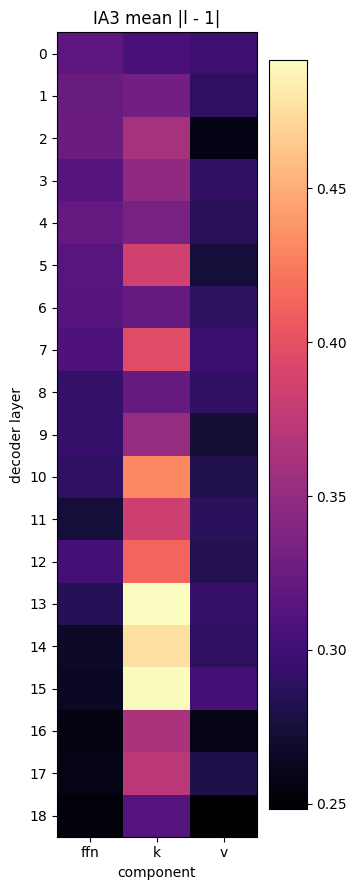


global mean |l - 1| = 0.3182
  The vectors moved substantially, so CELL 9's verdict is a real test of IA3,
  not a test of whether it got enough optimiser steps.


In [ ]:
# CELL 10 — IA3 INTERPRETATION: what did it inhibit and amplify?

import pandas as pd, matplotlib.pyplot as plt

rows = []
for li, blk in enumerate(decoder.layers):
    for tag, mod in (("k", blk.attn.k), ("v", blk.attn.v), ("ffn", blk.ffn.down)):
        l = mod.l.detach().cpu().float()
        rows.append({"layer": li, "component": tag, "n": l.numel(),
                     "mean_abs_dev": float((l - 1).abs().mean()),
                     "frac_amplified": float((l > 1.05).float().mean()),
                     "frac_inhibited": float((l < 0.95).float().mean()),
                     "min": float(l.min()), "max": float(l.max())})
df = pd.DataFrame(rows)

print("IA3 learned |l - 1| by component (l=1 is the pretrained function):")
print(df.groupby("component")[["mean_abs_dev","frac_amplified","frac_inhibited"]].mean().round(4))
print("\nmost adapted layers:")
print(df.groupby("layer")["mean_abs_dev"].mean().sort_values(ascending=False).head(6).round(4))
print(f"\nglobal range of l: [{df['min'].min():.3f}, {df['max'].max():.3f}]")

piv = df.pivot(index="layer", columns="component", values="mean_abs_dev")
fig, ax = plt.subplots(figsize=(3.6, 9))
im = ax.imshow(piv.values, cmap="magma", aspect="auto")
ax.set_xticks(range(len(piv.columns))); ax.set_xticklabels(piv.columns)
ax.set_yticks(range(len(piv.index)));   ax.set_yticklabels(piv.index)
ax.set_xlabel("component"); ax.set_ylabel("decoder layer")
ax.set_title("IA3 mean |l - 1|")
plt.colorbar(im); plt.tight_layout()
plt.savefig(OUTPUT_DIR / "ia3_scaling.png", dpi=120); plt.show()

gm = float(df["mean_abs_dev"].mean())
print(f"\nglobal mean |l - 1| = {gm:.4f}")
if gm < 0.02:
    print("  < 0.02 => the vectors barely left their init. Either the LR or the step")
    print("  count is too low (check `steps` in CELL 8), not that IA3 cannot work here.")
else:
    print("  The vectors moved substantially, so CELL 9's verdict is a real test of IA3,")
    print("  not a test of whether it got enough optimiser steps.")
df.to_csv(OUTPUT_DIR / "ia3_vectors.csv", index=False)

In [ ]:
# CELL 11 — PER-CLASS REPORT for the winning arm

if d_swa > 0:
    win, dev_e, crf_use, test_e = "B (IA3)", ia3_dev_e, ia3_crf, ia3_test_e
else:
    bi = int(np.argmax(frozen_swa))
    sdev, stest, scrf = frozen_state[bi]
    crf_use = swa_from(scrf)
    dev_e  = {d["doc_id"]: np.mean([b[d["doc_id"]] for b in sdev], 0)  for d in dev_docs}
    test_e = {d["doc_id"]: np.mean([b[d["doc_id"]] for b in stest], 0) for d in test_docs}
    win = f"A (frozen, seed {CFG.frozen_seeds[bi]})"
print(f"Reporting arm {win}\n")

ypd = [p for d in dev_docs
       for p in crf_use.viterbi(torch.tensor(dev_e[d["doc_id"]],
                 dtype=torch.float32, device=DEVICE))]
print(classification_report(ytd, ypd, labels=list(range(NUM_LABELS)),
                            target_names=[ID2LABEL[i] for i in range(NUM_LABELS)],
                            digits=4, zero_division=0))
sup = np.bincount(ytd, minlength=NUM_LABELS)
ok = [i for i in range(NUM_LABELS) if sup[i] > 0]
print(f"supported-only ({len(ok)}/{NUM_LABELS}): "
      f"{f1_score(ytd, ypd, labels=ok, average='macro', zero_division=0):.4f}")

def runlen(s):
    r, o = 1, []
    for i in range(1, len(s)):
        if s[i] == s[i-1]: r += 1
        else: o.append(r); r = 1
    o.append(r); return float(np.mean(o))
yp_arg = [int(np.argmax(dev_e[d["doc_id"]][i]))
          for d in dev_docs for i in range(len(d["labels"]))]
print(f"\nrun length  gold {runlen(ytd):.2f} | argmax {runlen(yp_arg):.2f} | "
      f"Viterbi {runlen(ypd):.2f}")
print(f"CRF decode delta: {macro_f1(ytd, ypd) - macro_f1(ytd, yp_arg):+.4f}")

Reporting arm B (IA3)

                        precision    recall  f1-score   support

                  Fact     0.6954    0.6171    0.6539       444
                 Issue     0.8571    0.4000    0.5455        15
    ArgumentPetitioner     0.7277    0.3875    0.5057       400
    ArgumentRespondent     0.4618    0.4449    0.4532       272
               Statute     0.8230    0.7750    0.7983       120
               Dissent     0.0000    0.0000    0.0000         0
   PrecedentReliedUpon     0.6301    0.5433    0.5835       254
PrecedentNotReliedUpon     0.3521    0.5000    0.4132        50
    PrecedentOverruled     0.0000    0.0000    0.0000         0
    RulingByLowerCourt     0.5500    0.3235    0.4074       102
    RatioOfTheDecision     0.4317    0.7841    0.5568       403
  RulingByPresentCourt     0.5952    0.5102    0.5495        49
                  None     0.3636    0.2424    0.2909        33

              accuracy                         0.5574      2142
             ma

In [ ]:
# CELL 12 — SUBMISSION from the winning arm

predictions = {}
for d in test_docs:
    e = torch.tensor(test_e[d["doc_id"]], dtype=torch.float32, device=DEVICE)
    path = crf_use.viterbi(e)
    assert len(path) == len(d["sentences"]), d["doc_id"]
    predictions[d["doc_id"]] = [ID2LABEL[int(p)] for p in path]
assert len(predictions) == len(test_docs)
assert all(l in LABEL2ID for v in predictions.values() for l in v)

pp = OUTPUT_DIR / "prediction.json"
json.dump(predictions, open(pp, "w", encoding="utf-8"), indent=2, ensure_ascii=False)
zp = OUTPUT_DIR / "submission.zip"
with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as zf: zf.write(pp, "prediction.json")
print(f"Saved {zp}  (arm {win})")

pc = Counter(l for v in predictions.values() for l in v)
ptot, ttot = sum(pc.values()), sum(cnt.values())
print(f"\nPredicted {len(pc)}/{NUM_LABELS} labels")
for i in sorted(range(NUM_LABELS), key=lambda i: -cnt.get(i, 0)):
    l = ID2LABEL[i]
    print(f"  {l:<26}{pc.get(l,0):>6}{100*pc.get(l,0)/ptot:>7.2f}%  train {100*cnt.get(i,0)/ttot:.2f}%")

json.dump({"armA_best_mean": A_best, "armA_best_std": A_best_sd,
           "armA_swa_mean": A_swa, "armA_swa_std": A_swa_sd,
           "armB_best": float(ia3_best), "armB_swa": float(ia3_swa),
           "delta_swa": float(d_swa), "bar": float(bar), "verdict": verdict,
           "ia3_params": int(n_ia3), "optimiser_steps": int(steps_total),
           "ia3_mean_abs_dev": gm, "history": hist},
          open(OUTPUT_DIR / "ia3_summary.json", "w"), indent=2)
print(f"\nSummary -> {OUTPUT_DIR/'ia3_summary.json'}")

Saved /content/drive/MyDrive/CS781_Phase3_IA3_outputs/submission.zip  (arm B (IA3))

Predicted 11/13 labels
  RatioOfTheDecision           795  36.19%  train 25.53%
  Fact                         394  17.93%  train 24.33%
  PrecedentReliedUpon          364  16.57%  train 11.55%
  ArgumentPetitioner           206   9.38%  train 9.58%
  ArgumentRespondent            79   3.60%  train 8.00%
  Statute                      173   7.87%  train 6.52%
  RulingByLowerCourt           103   4.69%  train 5.19%
  PrecedentNotReliedUpon         6   0.27%  train 3.38%
  RulingByPresentCourt          40   1.82%  train 1.82%
  None                          24   1.09%  train 1.76%
  Dissent                        0   0.00%  train 1.69%
  Issue                         13   0.59%  train 0.64%
  PrecedentOverruled             0   0.00%  train 0.02%

Summary -> /content/drive/MyDrive/CS781_Phase3_IA3_outputs/ia3_summary.json
